**Part 1 — Dataset, Problem & Feature/Target Identification**

1.	Load the dataset and briefly inspect it (shape, dtypes, first few rows, summary statistics).
2.	Identify the dependent variable and list the independent variables, split explicitly into numerical features and categorical features.
3.	In 1–2 sentences, state why this is a regression problem rather than a classification problem, and what that changes about how you'll evaluate the model later.



In [23]:
#	Load the dataset and briefly inspect it (shape, dtypes, first few rows, summary statistics).

import pandas as pd
import numpy as np

df=pd.read_csv('train.csv')
print("dataset shape:",df.shape)
print(df.dtypes)
print(df.head())
print(df.describe())
print(df.info())

dataset shape: (1460, 81)
Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN    

The dataset contains 1,460 rows and 81 columns. It includes both numerical and categorical features describing residential properties, along with the target variable SalePrice. The dataset contains 35 integer columns, 3 floating-point columns, and 43 string/categorical columns. Some columns contain missing values, which will need to be handled during data preparation.

2.	Identify the dependent variable and list the independent variables, split explicitly into numerical features and categorical features.

      *Dependent Variable (Target):*

      SalePrice

      *Independent Variables:*

      Numerical Features:

      OverallQual
      GrLivArea
      TotalBsmtSF
      GarageCars
      YearBuilt
      FullBath
      GarageArea

      Categorical Features:

      Neighborhood
      HouseStyle
      KitchenQual

3.	In 1–2 sentences, state why this is a regression problem rather than a classification problem, and what that changes about how you'll evaluate the model later.


      This is a regression problem because the target variable, SalePrice, is a continuous numerical value rather than a category or class. Therefore, the model will be evaluated using regression metrics such as MAE, MSE, RMSE, and R² instead of classification metrics such as accuracy, precision, and recall.

**Part 2 — Data Preparation & Train/Test Split**

4.	Prepare X (features) and y (price) for modeling: encode every categorical column into numeric form, and briefly justify your choice of encoding method for each type of column.
5.	Confirm X is fully numeric with no missing values.
6.	Split X and y into training and test sets (e.g. an 80/20 split) and report the resulting shapes.


In [24]:
#4.	Prepare X (features) and y (price) for modeling: encode every categorical column into numeric form, and briefly justify your choice of encoding method for each type of column.


y=df['SalePrice']
X = df[['OverallQual',  
        'GrLivArea',
        'TotalBsmtSF',
        'GarageCars',
        'YearBuilt',
        'FullBath',
        'GarageArea',
        'Neighborhood',
        'HouseStyle',
        'KitchenQual']]  # 7 numerical features 3 categorical features


X=pd.get_dummies(X, columns=['Neighborhood','HouseStyle', 'KitchenQual'],
            drop_first=True)
X = X.astype(int)
print("X shape:", X.shape)
print("y shape:", y.shape)




# print(X.dtypes)
# print(X.head())


X shape: (1460, 41)
y shape: (1460,)


In [25]:
# 5.	Confirm X is fully numeric with no missing values.

# confirm  x is  with no missing values and it is fully numeric 
print("Missing values:", X.isnull().sum().sum())
print("All columns numeric:", X.select_dtypes(include='number').shape[1] == X.shape[1])


Missing values: 0
All columns numeric: True


In [26]:
# 6.	Split X and y into training and test sets (e.g. an 80/20 split) and report the resulting shapes.


from sklearn.model_selection import train_test_split

X_train,X_test, y_train, y_test=train_test_split(
  X,
  y,
  test_size=0.20,
  random_state=42

)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1168, 41)
X_test shape: (292, 41)
y_train shape: (1168,)
y_test shape: (292,)


**Part 3 — Linear Regression & Predictions**

7.	Train a LinearRegression model on the training data.
8.	Generate predicted prices on the test set, and display a small table comparing actual vs. predicted price for 10 test houses.


In [27]:
# 7.	Train a LinearRegression model on the training data.
from sklearn.linear_model import LinearRegression


lr= LinearRegression().fit(X_train,y_train)

lr_predict = lr.predict(X_test)

In [28]:
# 8.	Generate predicted prices on the test set, and display a small table comparing actual vs. predicted price for 10 test houses.

comparison=pd.DataFrame({
   'Actual Price': y_test.values,
   'Predicted Price': lr_predict
})

print(comparison.head(10))

   Actual Price  Predicted Price
0        154500    137651.680553
1        325000    323719.185261
2        115000    111680.742397
3        159000    172513.418983
4        315500    317613.935354
5         75500     67209.611386
6        311500    232014.358072
7        146000    146860.821039
8         84500     66775.847241
9        135500    116934.045308


**Part 4 — Coefficients & Intercept**

9.	Extract the intercept and all coefficients. Build a table: Feature | Coefficient | Interpretation, with a one-line, plain-English interpretation for each feature (e.g. "each additional bathroom is associated with a price increase of approximately ___, holding other features constant").
10.	Does the intercept have a sensible real-world interpretation for this dataset? Why or why not?


In [31]:

# 9.	Extract the intercept and all coefficients. Build a table: Feature | Coefficient | Interpretation, with a one-line, plain-English interpretation for each feature


print("intercept",lr.intercept_)

co_efficients= pd.DataFrame({
  'Feature':X.columns,
  'Coefficient':lr.coef_
})

print(co_efficients)

intercept -418885.9150756721
                 Feature   Coefficient
0            OverallQual  13094.459115
1              GrLivArea     56.092028
2            TotalBsmtSF      5.603085
3             GarageCars   9402.548116
4              YearBuilt    216.882072
5               FullBath    -77.237331
6             GarageArea      7.312779
7   Neighborhood_Blueste   1646.708688
8    Neighborhood_BrDale   -781.409497
9   Neighborhood_BrkSide  23108.160550
10  Neighborhood_ClearCr  54989.900543
11  Neighborhood_CollgCr  24641.646465
12  Neighborhood_Crawfor  47068.885921
13  Neighborhood_Edwards   5345.353143
14  Neighborhood_Gilbert  25293.827860
15   Neighborhood_IDOTRR  12726.323461
16  Neighborhood_MeadowV   5399.017236
17  Neighborhood_Mitchel  15694.836602
18    Neighborhood_NAmes  15492.623262
19  Neighborhood_NPkVill  10799.215046
20   Neighborhood_NWAmes  17078.782057
21  Neighborhood_NoRidge  78288.811275
22  Neighborhood_NridgHt  58929.576827
23  Neighborhood_OldTown   5210.598

10.	Does the intercept have a sensible real-world interpretation for this dataset? Why or why not?

        The intercept of the Linear Regression model is approximately -418885.92. In a linear regression model, the intercept represents the predicted SalePrice when all input features are zero. However, this does not have a sensible real-world interpretation for this dataset because a house cannot realistically have all of its selected features equal to zero. Therefore, the intercept mainly serves as a mathematical part of the regression equation rather than a meaningful standalone house-price estimate.

**Part 5 — Residuals & Regression Metrics**
11.	Compute residuals on the test set and plot them (e.g. residuals vs. predicted values, and a histogram of residuals). Do the residuals look randomly scattered, or is there a visible pattern?
12.	Compute MAE, MSE, RMSE, and R² on the test set. Report them in a small table.
13.	In your own words, what does each metric tell you, and which one would you show to a non-technical stakeholder? Why?


892     16848.319447
1105     1280.814739
413      3319.257603
522    -13513.418983
1036    -2113.935354
Name: SalePrice, dtype: float64


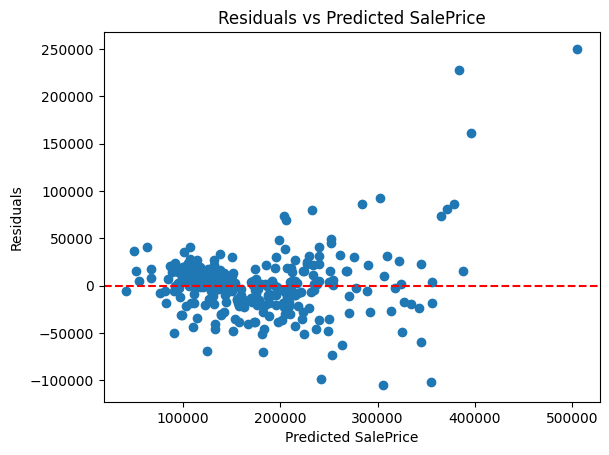

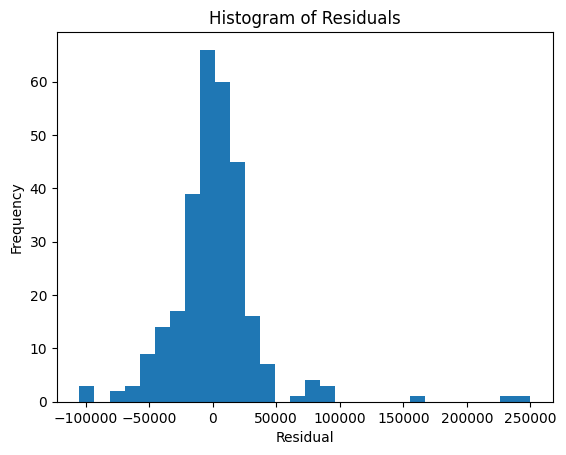

In [35]:
# 11.	Compute residuals on the test set and plot them (e.g. residuals vs. predicted values, and a histogram of residuals). Do the residuals look randomly scattered, or is there a visible pattern?


residuals = y_test-lr_predict
print(residuals.head())


import matplotlib.pyplot as plt

plt.scatter(lr_predict, residuals)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted SalePrice")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted SalePrice")
plt.show()


plt.hist(residuals, bins=30)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")
plt.show()

In [37]:
# 12.	Compute MAE, MSE, RMSE, and R² on the test set. Report them in a small table.

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
mae= mean_absolute_error(y_test, lr_predict)
mse=mean_squared_error(y_test, lr_predict)
rmse=np.sqrt(mse)
r2 = r2_score(y_test, lr_predict)

metrics = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Value': [mae, mse, rmse, r2]
})

print(metrics)

  Metric         Value
0    MAE  2.132196e+04
1    MSE  1.231137e+09
2   RMSE  3.508756e+04
3     R²  8.394935e-01


13.	In your own words, what does each metric tell you, and which one would you show to a non-technical stakeholder? Why?



**Part 6 — Training vs. Testing & Generalization**
14.	Compute MAE, MSE, RMSE, and R² on the training set, and place them side by side with your Part 5 test-set metrics in one comparison table.
15.	Is there a large gap between training and testing performance? What would a large gap suggest about overfitting or generalization, and what does your actual result suggest here?


In [39]:
# 14.	Compute MAE, MSE, RMSE, and R² on the training set, and place them side by side with your Part 5 test-set metrics in one comparison table.

lr_train= lr.predict(X_train)



mae2= mean_absolute_error(y_train, lr_train)
mse2=mean_squared_error(y_train, lr_train)
rmse2=np.sqrt(mse2)
r2_2 = r2_score(y_train, lr_train)

metrics2 = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Value': [mae2, mse2, rmse2, r2_2]
})

print(metrics2)
comparison_table = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Training': [mae2, mse2, rmse2, r2_2],
    'Testing': [mae, mse, rmse, r2]
})

print(comparison_table)

  Metric         Value
0    MAE  2.066246e+04
1    MSE  1.059392e+09
2   RMSE  3.254831e+04
3     R²  8.223852e-01
  Metric      Training       Testing
0    MAE  2.066246e+04  2.132196e+04
1    MSE  1.059392e+09  1.231137e+09
2   RMSE  3.254831e+04  3.508756e+04
3     R²  8.223852e-01  8.394935e-01


The training and testing metrics are relatively close to each other. The model has a training MAE of approximately 20,662 and a testing MAE of approximately 21,322, while the training RMSE is approximately 32,548 and the testing RMSE is approximately 35,088. The R² score is 0.822 on the training set and 0.839 on the testing set. Since the testing performance does not show a large deterioration compared with the training performance, there is no strong evidence of severe overfitting. The small differences between training and testing results suggest that the model generalizes reasonably well to the test data.

15.	Is there a large gap between training and testing performance? What would a large gap suggest about overfitting or generalization, and what does your actual result suggest here?

The training and testing results are relatively close, which suggests that the Linear Regression model generalizes reasonably well to unseen data. The testing MAE and RMSE are only slightly higher than the training values, while the testing R² is slightly higher than the training R². Therefore, there is no strong evidence of severe overfitting in this model. However, the residual analysis shows that the model does not capture all patterns in the house-price data, so there is still room for improvement through better feature engineering and more advanced regression techniq